# Final Modelling Dataset

**Project:** Predicting Performance Trajectories of Women Micro-Enterprises: An Early Warning Framework

This notebook converts the candidate features from Notebook 03 into a modelling-ready dataset.

Main goals:
1. Validate one-row-per-participant structure
2. Remove metadata and linkage fields from predictors
3. Re-check leakage
4. Review missingness and feature coverage
5. Review cohort coverage of competency deltas
6. Reduce obvious redundant behavior features
7. Separate numerical and categorical predictors
8. Save primary and sensitivity modelling datasets

No global imputation, scaling, or one-hot encoding is performed here. These steps must be fitted inside each modelling pipeline.

In [2]:
# 0. Setup

from google.colab import drive
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/24088950_MAI_Research")
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

ENGINEERED_PATH = OUTPUT_DIR / "engineered_features.csv"
FEATURE_DICTIONARY_PATH = OUTPUT_DIR / "candidate_feature_dictionary.csv"
DELTA_DICTIONARY_PATH = OUTPUT_DIR / "competency_delta_dictionary.csv"

print("Project folder:", PROJECT_DIR)
print("Output folder:", OUTPUT_DIR)
print("Engineered features:", ENGINEERED_PATH)
print("Engineered file exists:", ENGINEERED_PATH.exists())

Mounted at /content/drive
Project folder: /content/drive/MyDrive/24088950_MAI_Research
Output folder: /content/drive/MyDrive/24088950_MAI_Research/outputs
Engineered features: /content/drive/MyDrive/24088950_MAI_Research/outputs/engineered_features.csv
Engineered file exists: True


## 1. Load Notebook 03 Outputs

In [3]:
# 1. Load engineered dataset

if not ENGINEERED_PATH.exists():
    raise FileNotFoundError(
        "engineered_features.csv was not found. Run Notebook 03 first."
    )

engineered = pd.read_csv(ENGINEERED_PATH)

feature_dictionary = (
    pd.read_csv(FEATURE_DICTIONARY_PATH)
    if FEATURE_DICTIONARY_PATH.exists()
    else pd.DataFrame()
)

delta_dictionary = (
    pd.read_csv(DELTA_DICTIONARY_PATH)
    if DELTA_DICTIONARY_PATH.exists()
    else pd.DataFrame()
)

print("Engineered shape:", engineered.shape)
print("Unique participants:", engineered["Participant ID"].nunique())

display(engineered.head())

Engineered shape: (173, 55)
Unique participants: 173


,Participant ID,Performance Trajectory,Cohort ID,Funder/Program,Year,Age,State,Marital Status,Education Level,Working Status,...,delta_confident_with_product_packaging_appearance,delta_confident_in_the_quality_of_the_photos_you_share_for_business,delta_confident_in_the_quality_of_the_videos_you_share_for_business,delta_confident_to_deliver_an_elevator_pitch,delta_confident_in_managing_businees_finance,delta_understand_the_main_purpose_of_a_business_plan,delta_confident_i_can_prepare_a_complete_and_convincing_business_plan,delta_confident_speaking_in_front_of_audiences,overall_competency_change_z,competency_delta_items_available
0,2025_IBU-ACADEMY-MIB-C1-01,High,MIB-2025-C1,MIB,2025,26,SABAH,Married,Diploma,Self-Employed,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,2025_IBU-ACADEMY-MIB-C1-02,High,MIB-2025-C1,MIB,2025,26,JOHOR,Married,SPM,Self-Employed,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,2025_IBU-ACADEMY-MIB-C1-04,Moderate,MIB-2025-C1,MIB,2025,26,SELANGOR,Divorced,SPM,Self-Employed,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3,2025_IBU-ACADEMY-MIB-C1-05,Moderate,MIB-2025-C1,MIB,2025,26,NEGERI SEMBILAN,Married,Diploma,Self-Employed,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,2025_IBU-ACADEMY-MIB-C1-06,High,MIB-2025-C1,MIB,2025,26,KUALA LUMPUR,Divorced,SPM,Self-Employed,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


## 2. Validate Participant-Level Structure

In [4]:
# 2. Check duplicate participant rows

duplicate_ids = engineered["Participant ID"].value_counts()
duplicate_ids = duplicate_ids[duplicate_ids > 1]

if len(duplicate_ids) == 0:
    print("PASS: One row per Participant ID.")
else:
    print("WARNING: Duplicate participant rows detected.")
    display(
        duplicate_ids.rename("Rows")
        .reset_index()
        .rename(columns={"index": "Participant ID"})
    )

PASS: One row per Participant ID.


In [5]:
# 2.1 Validate target

TARGET_COLUMN = "Performance Trajectory"

if TARGET_COLUMN not in engineered.columns:
    raise KeyError(
        "Performance Trajectory was not found. Run Notebook 02 and Notebook 03 again."
    )

display(
    engineered[TARGET_COLUMN]
    .value_counts(dropna=False)
    .rename_axis("Class")
    .reset_index(name="Participants")
)

print(
    "Missing target values:",
    engineered[TARGET_COLUMN].isna().sum()
)

,Class,Participants
0,Moderate,84
1,High,46
2,Low,43


Missing target values: 0


## 3. Restrict to Valid Target Records

In [6]:
# 3. Keep only records with a valid target

model_data = engineered[
    engineered[TARGET_COLUMN].notna()
].copy()

print("Participants retained:", model_data["Participant ID"].nunique())
display(model_data[TARGET_COLUMN].value_counts())

Participants retained: 173


,count
Performance Trajectory,
Moderate,84
High,46
Low,43


## 4. Protect Metadata and Linkage Fields

Participant ID, cohort, programme and year remain available for audit and subgroup analysis, but are not automatically used as model predictors.

In [7]:
# 4. Save modelling metadata separately

metadata_columns = [
    "Participant ID",
    "Cohort ID",
    "Funder/Program",
    "Year",
    TARGET_COLUMN
]

metadata_columns = [
    c for c in metadata_columns
    if c in model_data.columns
]

model_metadata = model_data[metadata_columns].copy()

display(model_metadata.head())

,Participant ID,Cohort ID,Funder/Program,Year,Performance Trajectory
0,2025_IBU-ACADEMY-MIB-C1-01,MIB-2025-C1,MIB,2025,High
1,2025_IBU-ACADEMY-MIB-C1-02,MIB-2025-C1,MIB,2025,High
2,2025_IBU-ACADEMY-MIB-C1-04,MIB-2025-C1,MIB,2025,Moderate
3,2025_IBU-ACADEMY-MIB-C1-05,MIB-2025-C1,MIB,2025,Moderate
4,2025_IBU-ACADEMY-MIB-C1-06,MIB-2025-C1,MIB,2025,High


## 5. Predictor Policy

The primary model excludes baseline sales and baseline profit because the target itself is defined using baseline sales (S0).

A sensitivity dataset will also be created with baseline financial variables included.

In [8]:
# 5. Define initial candidate columns

non_predictor_columns = [
    "Participant ID",
    "Cohort ID",
    "Funder/Program",
    "Year",
    TARGET_COLUMN
]

baseline_financial_features = [
    "Sales Before Program",
    "Profit Before Program"
]

candidate_columns = [
    c for c in model_data.columns
    if c not in non_predictor_columns
]

print("Initial candidate predictors:", len(candidate_columns))

Initial candidate predictors: 50


## 6. Leakage Audit

In [9]:
# 6. Scan for potential leakage variables

leakage_keywords = [
    "sales month 1",
    "sales month 2",
    "sales month 3",
    "total sales",
    "average monthly sales",
    "sales growth",
    "profit month 1",
    "profit month 2",
    "profit month 3",
    "total profit",
    "profit growth",
    "post",
    "latest",
    "bonus payout",
    "performance trajectory"
]

leakage_flags = []

for column in model_data.columns:
    lower = str(column).lower()
    matched = [k for k in leakage_keywords if k in lower]

    if matched:
        leakage_flags.append({
            "Feature": column,
            "Matched Keyword": ", ".join(matched)
        })

leakage_flags = pd.DataFrame(leakage_flags)

if len(leakage_flags):
    display(leakage_flags)
else:
    print("No obvious leakage columns detected by name.")

,Feature,Matched Keyword
0,Performance Trajectory,performance trajectory


In [10]:
# 6.1 Exclude known leakage columns

known_leakage = []

for column in candidate_columns:
    lower = str(column).lower()

    if any(k in lower for k in leakage_keywords):
        known_leakage.append(column)

candidate_columns = [
    c for c in candidate_columns
    if c not in known_leakage
]

print("Known leakage variables excluded:", len(known_leakage))

for column in known_leakage:
    print("-", column)

Known leakage variables excluded: 0


## 7. Remove Empty and Constant Features

In [11]:
# 7. Detect empty and constant predictors

empty_features = []
constant_features = []

for column in candidate_columns:
    observed = model_data[column].dropna()

    if len(observed) == 0:
        empty_features.append(column)
    elif observed.nunique() <= 1:
        constant_features.append(column)

print("Empty features:", len(empty_features))
print("Constant features:", len(constant_features))

Empty features: 0
Constant features: 0


In [12]:
# 7.1 Remove unusable features

candidate_columns = [
    c for c in candidate_columns
    if c not in empty_features + constant_features
]

print(
    "Candidate predictors after unusable-feature removal:",
    len(candidate_columns)
)

Candidate predictors after unusable-feature removal: 50


## 8. Missingness Review

In [13]:
# 8. Review feature coverage

HIGH_MISSING_THRESHOLD = 50.0
MIN_AVAILABLE_N = 30

missingness_review = []

for column in candidate_columns:
    available_n = model_data[column].notna().sum()
    missing_pct = model_data[column].isna().mean() * 100

    missingness_review.append({
        "Feature": column,
        "Available n": int(available_n),
        "Missing %": round(missing_pct, 1),
        "Unique Values": model_data[column].nunique(dropna=True)
    })

missingness_review = (
    pd.DataFrame(missingness_review)
    .sort_values("Missing %", ascending=False)
)

display(missingness_review)

,Feature,Available n,Missing %,Unique Values
43,delta_confident_to_deliver_an_elevator_pitch,22,87.3,5
46,delta_confident_i_can_prepare_a_complete_and_c...,22,87.3,6
45,delta_understand_the_main_purpose_of_a_busines...,22,87.3,5
39,delta_comfortable_working_and_sharing_ideas_in...,23,86.7,4
36,delta_i_am_confident_with_the_price_i_set,23,86.7,5
34,delta_well_know_who_target_customer,23,86.7,5
38,delta_level_of_courage_in_answering_spontaneou...,23,86.7,5
35,delta_know_the_pain_point_customer_face_that_m...,23,86.7,5
47,delta_confident_speaking_in_front_of_audiences,23,86.7,4
32,delta_able_to_identify_3_personal_strengths_an...,25,85.5,5


In [14]:
# 8.1 Flag low-coverage features

low_coverage_features = (
    missingness_review[
        (missingness_review["Missing %"] > HIGH_MISSING_THRESHOLD)
        | (missingness_review["Available n"] < MIN_AVAILABLE_N)
    ]["Feature"]
    .tolist()
)

print("Low-coverage features flagged:", len(low_coverage_features))

for column in low_coverage_features:
    print("-", column)

Low-coverage features flagged: 16
- delta_confident_to_deliver_an_elevator_pitch
- delta_confident_i_can_prepare_a_complete_and_convincing_business_plan
- delta_understand_the_main_purpose_of_a_business_plan
- delta_comfortable_working_and_sharing_ideas_in_a_team
- delta_i_am_confident_with_the_price_i_set
- delta_well_know_who_target_customer
- delta_level_of_courage_in_answering_spontaneous_questions_q_a_from_panel_members_or_investors
- delta_know_the_pain_point_customer_face_that_makes_them_need_productsa
- delta_confident_speaking_in_front_of_audiences
- delta_able_to_identify_3_personal_strengths_and_3_weaknesses
- delta_confident_with_product_packaging_appearance
- delta_confident_in_managing_businees_finance
- delta_confident_in_the_quality_of_the_videos_you_share_for_business
- delta_confident_in_the_quality_of_the_photos_you_share_for_business
- delta_confidence_level_in_your_leadership
- delta_confidence_level_in_pitching_your_business_idea_in_front_of_judges_or_a_large_audi

## 9. Cohort Coverage of Competency Delta Features

In [15]:
# 9. Review competency delta coverage across cohorts

delta_columns = [
    c for c in candidate_columns
    if c.startswith("delta_")
]

MIN_DELTA_COHORTS = 2
MIN_DELTA_OBS = 30

delta_coverage_rows = []

for column in delta_columns:
    observed = model_data[
        model_data[column].notna()
    ][["Cohort ID", column]]

    delta_coverage_rows.append({
        "Feature": column,
        "Available n": len(observed),
        "Cohorts with Data": observed["Cohort ID"].nunique(),
        "Coverage %": round(
            len(observed) / len(model_data) * 100,
            1
        )
    })

delta_cohort_coverage = pd.DataFrame(delta_coverage_rows)

if len(delta_cohort_coverage):
    delta_cohort_coverage = delta_cohort_coverage.sort_values(
        ["Cohorts with Data", "Available n"],
        ascending=False
    )
    display(delta_cohort_coverage)
else:
    print("No competency delta features detected.")

,Feature,Available n,Cohorts with Data,Coverage %
5,delta_confidence_level_in_pitching_your_busine...,40,2,23.1
1,delta_confidence_level_in_your_leadership,36,2,20.8
0,delta_able_to_identify_3_personal_strengths_an...,25,1,14.5
8,delta_confident_with_product_packaging_appearance,25,1,14.5
9,delta_confident_in_the_quality_of_the_photos_y...,25,1,14.5
10,delta_confident_in_the_quality_of_the_videos_y...,25,1,14.5
12,delta_confident_in_managing_businees_finance,25,1,14.5
2,delta_well_know_who_target_customer,23,1,13.3
3,delta_know_the_pain_point_customer_face_that_m...,23,1,13.3
4,delta_i_am_confident_with_the_price_i_set,23,1,13.3


In [16]:
# 9.1 Select cross-cohort competency deltas

if len(delta_cohort_coverage):
    selected_delta_features = (
        delta_cohort_coverage[
            (delta_cohort_coverage["Cohorts with Data"] >= MIN_DELTA_COHORTS)
            & (delta_cohort_coverage["Available n"] >= MIN_DELTA_OBS)
        ]["Feature"]
        .tolist()
    )
else:
    selected_delta_features = []

print("Selected competency delta features:", len(selected_delta_features))

for column in selected_delta_features:
    print("-", column)

Selected competency delta features: 2
- delta_confidence_level_in_pitching_your_business_idea_in_front_of_judges_or_a_large_audience
- delta_confidence_level_in_your_leadership


## 10. Behavior Feature Selection

The primary model uses a smaller behavior set to reduce redundancy and improve comparability across cohorts.

In [17]:
# 10. Select primary behavior features

preferred_behavior_features = [
    "behavior_avg_gain_per_session",
    "behavior_avg_deduct_per_session",
    "behavior_final_z_in_cohort"
]

preferred_behavior_features = [
    c for c in preferred_behavior_features
    if c in model_data.columns
]

all_behavior_features = [
    c for c in candidate_columns
    if c.startswith("behavior_")
]

behavior_features_not_primary = [
    c for c in all_behavior_features
    if c not in preferred_behavior_features
]

print("Primary behavior features:")
for column in preferred_behavior_features:
    print("-", column)

Primary behavior features:
- behavior_avg_gain_per_session
- behavior_avg_deduct_per_session
- behavior_final_z_in_cohort


## 11. Engagement Timing Check

Attendance and Behavior Points should only be predictors if they are measured before the financial outcome window used for the target.

Change the flag to `False` if this timing is not valid for the selected cohorts.

In [18]:
# 11. Confirm engagement timing

ENGAGEMENT_TIMING_VALID = True

engagement_features = [
    "attendance_rate"
] + preferred_behavior_features

engagement_features = [
    c for c in engagement_features
    if c in model_data.columns
]

approved_engagement_features = (
    engagement_features
    if ENGAGEMENT_TIMING_VALID
    else []
)

print("Approved engagement features:")
for column in approved_engagement_features:
    print("-", column)

Approved engagement features:
- attendance_rate
- behavior_avg_gain_per_session
- behavior_avg_deduct_per_session
- behavior_final_z_in_cohort


## 12. Digital Readiness Features

In [19]:
# 12. Select baseline digital features

digital_features = [
    "digital_platform_count",
    "IG_followers_pre",
    "FB_followers_pre",
    "TT_followers_pre"
]

digital_features = [
    c for c in digital_features
    if c in model_data.columns
]

print("Digital predictors:")

for column in digital_features:
    print("-", column)

Digital predictors:
- digital_platform_count
- IG_followers_pre
- FB_followers_pre
- TT_followers_pre


## 13. Socio-Demographic and Formalisation Features

In [20]:
# 13. Select socio-demographic and formalisation predictors

sociodemographic_features = [
    "Age",
    "State",
    "Education Level",
    "Working Status",
    "Industry/Business Sector",
    "Years in Business",
    "Household Income",
    "Estimated Remaining Balance",
    "ssm_registered_binary"
]

sociodemographic_features = [
    c for c in sociodemographic_features
    if c in model_data.columns
]

print("Socio-demographic / formalisation predictors:")

for column in sociodemographic_features:
    print("-", column)

Socio-demographic / formalisation predictors:
- Age
- State
- Education Level
- Working Status
- Industry/Business Sector
- Years in Business
- Household Income
- Estimated Remaining Balance
- ssm_registered_binary


#13.1 Categorical Harmonisation

In [21]:
# 13.1 Harmonise industry categories

def harmonise_industry(value):

    if pd.isna(value):
        return np.nan

    text = str(value).strip().upper()

    categories = []

    if any(
        word in text
        for word in [
            "F&B",
            "FOOD",
            "BEVERAGE",
            "BAKERY",
            "CATERING",
            "CAKE",
            "COOKIE"
        ]
    ):
        categories.append("Food & Beverage")

    if any(
        word in text
        for word in [
            "CLOTHING",
            "FASHION",
            "APPAREL",
            "HIJAB",
            "TUDUNG",
            "TEXTILE"
        ]
    ):
        categories.append("Fashion & Apparel")

    if any(
        word in text
        for word in [
            "BEAUTY",
            "COSMETIC",
            "SKINCARE",
            "SPA"
        ]
    ):
        categories.append("Beauty & Personal Care")

    if any(
        word in text
        for word in [
            "CRAFT",
            "HANDICRAFT",
            "SONGKET"
        ]
    ):
        categories.append("Handicraft")

    if any(
        word in text
        for word in [
            "SERVICE",
            "SERVICES",
            "RENTAL",
            "CONSULT",
            "TUITION"
        ]
    ):
        categories.append("Services")

    categories = list(
        dict.fromkeys(categories)
    )

    if len(categories) == 0:
        return "Other"

    if len(categories) == 1:
        return categories[0]

    return "Multiple Sectors"


if "Industry/Business Sector" in model_data.columns:

    model_data[
        "Industry/Business Sector"
    ] = (
        model_data[
            "Industry/Business Sector"
        ]
        .map(harmonise_industry)
    )


print(
    model_data[
        "Industry/Business Sector"
    ].value_counts(
        dropna=False
    )
)

Industry/Business Sector
Food & Beverage           101
Multiple Sectors           30
Services                   12
Beauty & Personal Care     11
Handicraft                  9
Other                       6
Fashion & Apparel           4
Name: count, dtype: int64


In [22]:
# 13.2 Harmonise state categories

def harmonise_state(value):

    if pd.isna(value):
        return np.nan

    text = str(value).strip().upper()

    mapping = {
        "KL": "Kuala Lumpur",
        "KUALA LUMPUR": "Kuala Lumpur",
        "W.P KUALA LUMPUR": "Kuala Lumpur",
        "WP KUALA LUMPUR": "Kuala Lumpur",
        "WILAYAH PERSEKUTUAN KUALA LUMPUR": "Kuala Lumpur",
        "SELANGOR": "Selangor",
        "JOHOR": "Johor",
        "PAHANG": "Pahang",
        "PERAK": "Perak",
        "KEDAH": "Kedah",
        "PERLIS": "Perlis",
        "PULAU PINANG": "Pulau Pinang",
        "PENANG": "Pulau Pinang",
        "NEGERI SEMBILAN": "Negeri Sembilan",
        "MELAKA": "Melaka",
        "MALACCA": "Melaka",
        "TERENGGANU": "Terengganu",
        "KELANTAN": "Kelantan",
        "SABAH": "Sabah",
        "SARAWAK": "Sarawak"
    }

    return mapping.get(
        text,
        str(value).strip().title()
    )


if "State" in model_data.columns:

    model_data[
        "State"
    ] = (
        model_data[
            "State"
        ]
        .map(harmonise_state)
    )


print(
    model_data[
        "State"
    ].value_counts(
        dropna=False
    )
)

State
Selangor           88
Kuala Lumpur       28
Johor              24
NaN                16
Pahang              3
Melaka              3
Negeri Sembilan     2
Kelantan            2
Perlis              2
Kedah               2
Sabah               1
Perak               1
Putrajaya           1
Name: count, dtype: int64


In [23]:
# 13.3 Select competency-change feature

competency_features = [
    "overall_competency_change_z"
]

competency_features = [
    c for c in competency_features
    if c in model_data.columns
]

print(
    "Competency predictors:"
)

for column in competency_features:
    print("-", column)

Competency predictors:
- overall_competency_change_z


In [24]:
# 13.4 Harmonise working status

if "Working Status" in model_data.columns:

    model_data[
        "Working Status"
    ] = (
        model_data[
            "Working Status"
        ]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    working_status_map = {
        "self-employed":
            "Self-Employed",

        "self employed":
            "Self-Employed",

        "selfemployed":
            "Self-Employed",

        "housewife":
            "Housewife",

        "unemployed":
            "Unemployed",

        "employed":
            "Employed",

        "part-time":
            "Part-Time",

        "part time":
            "Part-Time"
    }

    model_data[
        "Working Status"
    ] = (
        model_data[
            "Working Status"
        ]
        .replace(
            working_status_map
        )
    )


print(
    model_data[
        "Working Status"
    ]
    .value_counts(
        dropna=False
    )
)

Working Status
Self-Employed                                 159
Housewife                                       6
Part-Time                                       4
rm1500                                          1
houswife                                        1
freelance - stunt / talent (entertainment)      1
not working / housewife                         1
Name: count, dtype: Int64


## 14. Build Primary Predictor Set

In [25]:
# 14. Build primary predictor set

primary_features = (
    sociodemographic_features
    + digital_features
    + approved_engagement_features
    + competency_features
)
primary_features = list(dict.fromkeys(primary_features))

primary_features = [
    c for c in primary_features
    if c not in low_coverage_features
]

print("Primary predictors selected:", len(primary_features))

for column in primary_features:
    print("-", column)

Primary predictors selected: 18
- Age
- State
- Education Level
- Working Status
- Industry/Business Sector
- Years in Business
- Household Income
- Estimated Remaining Balance
- ssm_registered_binary
- digital_platform_count
- IG_followers_pre
- FB_followers_pre
- TT_followers_pre
- attendance_rate
- behavior_avg_gain_per_session
- behavior_avg_deduct_per_session
- behavior_final_z_in_cohort
- overall_competency_change_z


## 15. Build Sensitivity Predictor Set

In [26]:
# 15. Add baseline financial variables for sensitivity analysis

available_baseline_financial = [
    c for c in baseline_financial_features
    if c in model_data.columns
]

sensitivity_features = list(
    dict.fromkeys(
        primary_features
        + available_baseline_financial
    )
)

print("Sensitivity predictors:", len(sensitivity_features))
print(
    "Added baseline financial variables:",
    available_baseline_financial
)

Sensitivity predictors: 20
Added baseline financial variables: ['Sales Before Program', 'Profit Before Program']


## 16. Predictor Type Audit

In [27]:
# 16. Separate numeric and categorical predictors

primary_X = model_data[
    primary_features
].copy()

numeric_features = (
    primary_X
    .select_dtypes(include=[np.number])
    .columns
    .tolist()
)

categorical_features = [
    c for c in primary_features
    if c not in numeric_features
]

print("Numeric predictors:", len(numeric_features))
for column in numeric_features:
    print("-", column)

print("\nCategorical predictors:", len(categorical_features))
for column in categorical_features:
    print("-", column)

Numeric predictors: 14
- Age
- Years in Business
- Household Income
- Estimated Remaining Balance
- ssm_registered_binary
- digital_platform_count
- IG_followers_pre
- FB_followers_pre
- TT_followers_pre
- attendance_rate
- behavior_avg_gain_per_session
- behavior_avg_deduct_per_session
- behavior_final_z_in_cohort
- overall_competency_change_z

Categorical predictors: 4
- State
- Education Level
- Working Status
- Industry/Business Sector


## 17. Correlation and Redundancy Review

In [28]:
# 17. Numeric predictor Spearman correlation

if len(numeric_features) >= 2:
    numeric_corr = (
        model_data[numeric_features]
        .corr(
            method="spearman",
            min_periods=20
        )
    )

    display(numeric_corr.round(2))
else:
    numeric_corr = pd.DataFrame()
    print("Not enough numeric predictors for correlation analysis.")

,Age,Years in Business,Household Income,Estimated Remaining Balance,ssm_registered_binary,digital_platform_count,IG_followers_pre,FB_followers_pre,TT_followers_pre,attendance_rate,behavior_avg_gain_per_session,behavior_avg_deduct_per_session,behavior_final_z_in_cohort,overall_competency_change_z
Age,1.00,0.09,0.07,-0.13,-0.09,0.36,-0.16,-0.23,-0.13,0.19,-0.16,0.02,0.06,-0.06
Years in Business,0.09,1.00,-0.02,-0.11,0.07,-0.00,0.28,0.30,0.06,-0.00,-0.02,0.08,-0.18,-0.28
Household Income,0.07,-0.02,1.00,0.02,0.07,0.09,0.08,0.10,0.03,-0.04,-0.01,-0.15,0.01,0.00
Estimated Remaining Balance,-0.13,-0.11,0.02,1.00,-0.03,-0.05,-0.09,-0.18,-0.16,-0.09,-0.07,-0.03,-0.04,0.07
ssm_registered_binary,-0.09,0.07,0.07,-0.03,1.00,0.12,-0.05,0.13,0.03,-0.13,0.17,-0.09,-0.03,-0.08
digital_platform_count,0.36,-0.00,0.09,-0.05,0.12,1.00,0.06,-0.07,0.01,-0.14,0.04,0.07,-0.12,-0.04
IG_followers_pre,-0.16,0.28,0.08,-0.09,-0.05,0.06,1.00,0.50,0.19,0.15,-0.09,0.02,0.00,-0.22
FB_followers_pre,-0.23,0.30,0.10,-0.18,0.13,-0.07,0.50,1.00,0.33,-0.20,0.07,0.04,-0.13,-0.24
TT_followers_pre,-0.13,0.06,0.03,-0.16,0.03,0.01,0.19,0.33,1.00,-0.12,-0.08,0.04,-0.04,-0.37
attendance_rate,0.19,-0.00,-0.04,-0.09,-0.13,-0.14,0.15,-0.20,-0.12,1.00,-0.39,0.06,0.22,0.17


In [29]:
# 17.1 Detect highly correlated predictor pairs

REDUNDANCY_THRESHOLD = 0.80
high_corr_pairs = []

if len(numeric_corr):

    for i in range(len(numeric_corr.columns)):
        for j in range(i + 1, len(numeric_corr.columns)):

            var1 = numeric_corr.columns[i]
            var2 = numeric_corr.columns[j]
            rho = numeric_corr.iloc[i, j]

            if pd.notna(rho) and abs(rho) >= REDUNDANCY_THRESHOLD:

                high_corr_pairs.append({
                    "Variable 1": var1,
                    "Variable 2": var2,
                    "Spearman rho": rho,
                    "Absolute rho": abs(rho)
                })

high_corr_pairs = pd.DataFrame(high_corr_pairs)

if len(high_corr_pairs):
    high_corr_pairs = high_corr_pairs.sort_values(
        "Absolute rho",
        ascending=False
    )
    display(high_corr_pairs)
else:
    print("No numeric predictor pairs with |rho| >= 0.80.")

No numeric predictor pairs with |rho| >= 0.80.


## 18. Class Distribution and Sample Size

In [30]:
# 18. Final target distribution

class_distribution = (
    model_data[TARGET_COLUMN]
    .value_counts()
    .rename_axis("Class")
    .reset_index(name="Participants")
)

class_distribution["Percentage"] = (
    class_distribution["Participants"]
    / class_distribution["Participants"].sum()
    * 100
).round(2)

display(class_distribution)

,Class,Participants,Percentage
0,Moderate,84,48.55
1,High,46,26.59
2,Low,43,24.86


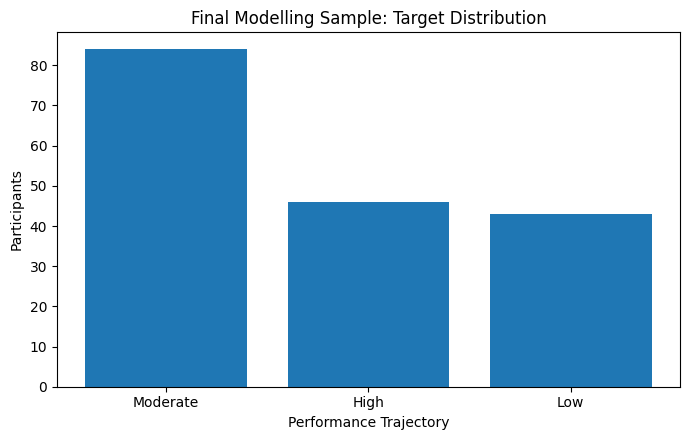

In [31]:
# 18.1 Plot class distribution

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.bar(
    class_distribution["Class"],
    class_distribution["Participants"]
)

ax.set_title(
    "Final Modelling Sample: Target Distribution"
)

ax.set_xlabel("Performance Trajectory")
ax.set_ylabel("Participants")

plt.tight_layout()
plt.show()

## 19. Create Final Modelling Tables

Participant ID is excluded from the predictor tables and saved separately in the modelling metadata file.

In [32]:
# 19. Create primary and sensitivity datasets

final_primary = model_data[
    primary_features
    + [TARGET_COLUMN]
].copy()

final_sensitivity = model_data[
    sensitivity_features
    + [TARGET_COLUMN]
].copy()

print("Primary dataset shape:", final_primary.shape)
print("Sensitivity dataset shape:", final_sensitivity.shape)

Primary dataset shape: (173, 19)
Sensitivity dataset shape: (173, 21)


## 20. Final Sanity Checks

In [33]:
# 20. Sanity checks

checks = {
    "Primary rows": len(final_primary),
    "Primary predictors": len(primary_features),
    "Sensitivity predictors": len(sensitivity_features),
    "Missing targets": int(
        final_primary[TARGET_COLUMN].isna().sum()
    ),
    "Duplicate final rows": int(
        final_primary.duplicated().sum()
    ),
    "Duplicate participant IDs in metadata": int(
        model_metadata["Participant ID"].duplicated().sum()
    )
}

display(
    pd.DataFrame(
        checks.items(),
        columns=["Check", "Value"]
    )
)

,Check,Value
0,Primary rows,173
1,Primary predictors,18
2,Sensitivity predictors,20
3,Missing targets,0
4,Duplicate final rows,0
5,Duplicate participant IDs in metadata,0


## 21. Build Feature Manifest

In [34]:
# 21. Feature manifest

manifest_rows = []

for column in primary_features:

    if column in competency_features:
        group = "Competency Delta"
    elif column in digital_features:
        group = "Digital Readiness"
    elif column in approved_engagement_features:
        group = "Engagement / Behavior"
    elif column in sociodemographic_features:
        group = "Socio-Demographic / Formalisation"
    else:
        group = "Other"

    manifest_rows.append({
        "Feature": column,
        "Feature Group": group,
        "Primary Model": "Yes",
        "Sensitivity Model": "Yes",
        "Data Type": (
            "Numeric"
            if column in numeric_features
            else "Categorical"
        )
    })

for column in available_baseline_financial:

    manifest_rows.append({
        "Feature": column,
        "Feature Group": "Baseline Financial",
        "Primary Model": "No",
        "Sensitivity Model": "Yes",
        "Data Type": "Numeric"
    })

feature_manifest = pd.DataFrame(manifest_rows)

display(feature_manifest)

,Feature,Feature Group,Primary Model,Sensitivity Model,Data Type
0,Age,Socio-Demographic / Formalisation,Yes,Yes,Numeric
1,State,Socio-Demographic / Formalisation,Yes,Yes,Categorical
2,Education Level,Socio-Demographic / Formalisation,Yes,Yes,Categorical
3,Working Status,Socio-Demographic / Formalisation,Yes,Yes,Categorical
4,Industry/Business Sector,Socio-Demographic / Formalisation,Yes,Yes,Categorical
5,Years in Business,Socio-Demographic / Formalisation,Yes,Yes,Numeric
6,Household Income,Socio-Demographic / Formalisation,Yes,Yes,Numeric
7,Estimated Remaining Balance,Socio-Demographic / Formalisation,Yes,Yes,Numeric
8,ssm_registered_binary,Socio-Demographic / Formalisation,Yes,Yes,Numeric
9,digital_platform_count,Digital Readiness,Yes,Yes,Numeric


## 22. Build Feature Exclusion Audit

In [35]:
# 22. Record excluded features and reasons

exclusion_rows = []

for column in known_leakage:
    exclusion_rows.append({
        "Feature": column,
        "Reason": "Potential outcome leakage"
    })

for column in empty_features:
    exclusion_rows.append({
        "Feature": column,
        "Reason": "No observed values"
    })

for column in constant_features:
    exclusion_rows.append({
        "Feature": column,
        "Reason": "No variation"
    })

for column in low_coverage_features:
    exclusion_rows.append({
        "Feature": column,
        "Reason": "Low coverage / high missingness"
    })

for column in behavior_features_not_primary:
    exclusion_rows.append({
        "Feature": column,
        "Reason": "Behavior redundancy / cohort comparability"
    })

for column in delta_columns:

    if (
        column not in selected_delta_features
        and column in candidate_columns
    ):
        exclusion_rows.append({
            "Feature": column,
            "Reason": "Insufficient cross-cohort competency coverage"
        })

for column in available_baseline_financial:
    exclusion_rows.append({
        "Feature": column,
        "Reason": "Excluded from primary model; retained for sensitivity analysis"
    })

feature_exclusion_audit = (
    pd.DataFrame(exclusion_rows)
    .drop_duplicates()
)

display(feature_exclusion_audit)

,Feature,Reason
0,delta_confident_to_deliver_an_elevator_pitch,Low coverage / high missingness
1,delta_confident_i_can_prepare_a_complete_and_c...,Low coverage / high missingness
2,delta_understand_the_main_purpose_of_a_busines...,Low coverage / high missingness
3,delta_comfortable_working_and_sharing_ideas_in...,Low coverage / high missingness
4,delta_i_am_confident_with_the_price_i_set,Low coverage / high missingness
5,delta_well_know_who_target_customer,Low coverage / high missingness
6,delta_level_of_courage_in_answering_spontaneou...,Low coverage / high missingness
7,delta_know_the_pain_point_customer_face_that_m...,Low coverage / high missingness
8,delta_confident_speaking_in_front_of_audiences,Low coverage / high missingness
9,delta_able_to_identify_3_personal_strengths_an...,Low coverage / high missingness


## 23. Save Notebook 04 Outputs

In [36]:
# 23. Save outputs to Google Drive

PRIMARY_PATH = (
    OUTPUT_DIR
    / "final_modelling_dataset_primary.csv"
)

SENSITIVITY_PATH = (
    OUTPUT_DIR
    / "final_modelling_dataset_sensitivity.csv"
)

METADATA_PATH = (
    OUTPUT_DIR
    / "modelling_participant_metadata.csv"
)

MANIFEST_PATH = (
    OUTPUT_DIR
    / "model_feature_manifest.csv"
)

EXCLUSION_PATH = (
    OUTPUT_DIR
    / "feature_exclusion_audit.csv"
)

CLASS_PATH = (
    OUTPUT_DIR
    / "final_target_distribution.csv"
)

REDUNDANCY_PATH = (
    OUTPUT_DIR
    / "high_correlation_pairs.csv"
)

final_primary.to_csv(
    PRIMARY_PATH,
    index=False
)

final_sensitivity.to_csv(
    SENSITIVITY_PATH,
    index=False
)

model_metadata.to_csv(
    METADATA_PATH,
    index=False
)

feature_manifest.to_csv(
    MANIFEST_PATH,
    index=False
)

feature_exclusion_audit.to_csv(
    EXCLUSION_PATH,
    index=False
)

class_distribution.to_csv(
    CLASS_PATH,
    index=False
)

high_corr_pairs.to_csv(
    REDUNDANCY_PATH,
    index=False
)

print("Saved:")
print("-", PRIMARY_PATH)
print("-", SENSITIVITY_PATH)
print("-", METADATA_PATH)
print("-", MANIFEST_PATH)
print("-", EXCLUSION_PATH)
print("-", CLASS_PATH)
print("-", REDUNDANCY_PATH)

Saved:
- /content/drive/MyDrive/24088950_MAI_Research/outputs/final_modelling_dataset_primary.csv
- /content/drive/MyDrive/24088950_MAI_Research/outputs/final_modelling_dataset_sensitivity.csv
- /content/drive/MyDrive/24088950_MAI_Research/outputs/modelling_participant_metadata.csv
- /content/drive/MyDrive/24088950_MAI_Research/outputs/model_feature_manifest.csv
- /content/drive/MyDrive/24088950_MAI_Research/outputs/feature_exclusion_audit.csv
- /content/drive/MyDrive/24088950_MAI_Research/outputs/final_target_distribution.csv
- /content/drive/MyDrive/24088950_MAI_Research/outputs/high_correlation_pairs.csv


In [37]:
# 24. Final summary

print("NOTEBOOK 04 SUMMARY")
print()

print(
    "Final modelling participants:",
    len(final_primary)
)

print(
    "Primary predictors:",
    len(primary_features)
)

print(
    "Sensitivity predictors:",
    len(sensitivity_features)
)

print(
    "Numeric primary predictors:",
    len(numeric_features)
)

print(
    "Categorical primary predictors:",
    len(categorical_features)
)

print(
    "Competency predictors:",
    len(
        competency_features
    )
)

print()
print(
    "Next notebook: 05_Logistic_Regression.ipynb"
)

NOTEBOOK 04 SUMMARY

Final modelling participants: 173
Primary predictors: 18
Sensitivity predictors: 20
Numeric primary predictors: 14
Categorical primary predictors: 4
Competency predictors: 1

Next notebook: 05_Logistic_Regression.ipynb
